In [2]:
import pandas as pd
import numpy as np
import json
from pathlib import Path

In [3]:
PROJECT_ROOT = Path.cwd().parent

PLAYERS_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "players_2025_26.csv"
)

STATS_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "player_statistics_2025_26.json"
)

In [4]:
players = pd.read_csv(PLAYERS_FILE)

with open(
    STATS_FILE,
    "r",
    encoding="utf-8"
) as file:
    stats_raw = json.load(file)

print("Jogadores:", players.shape)
print("Estatísticas:", len(stats_raw))

Jogadores: (574, 12)
Estatísticas: 574


In [5]:
players["birth_date"] = pd.to_datetime(
    players["birth_date"],
    errors="coerce",
    utc=True
)

players["is_u23"] = players["is_u23"].astype(
    "boolean"
)

In [6]:
stats_rows = []

for item in stats_raw:

    stats = item["data"]["statistics"].copy()

    stats["player_id"] = item["player_id"]

    stats_rows.append(stats)

stats = pd.DataFrame(stats_rows)

In [7]:
stats.shape

(574, 118)

In [8]:
stats.head()

,rating,totalRating,countRating,goals,bigChancesCreated,bigChancesMissed,assists,expectedAssists,goalsAssistsSum,expectedGoalsInvolvement,...,totwAppearances,goalKicks,ballRecovery,outfielderBlocks,id,type,appearances,statisticsType,player_id,expectedGoals
0,7.650000,15.3,2,0,0,0,0,0.000687,0,0.000687,...,1,17,17,0.0,2859975,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",1961855,NaN
1,7.551724,219.0,29,2,3,0,3,2.172791,5,3.395491,...,6,23,147,16.0,2110628,overall,29,"{'sportSlug': 'football', 'statisticsType': 'p...",1001196,1.2227
2,7.500000,15.0,2,0,0,0,0,0.001031,0,0.001031,...,1,8,15,0.0,2167029,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",983550,NaN
3,7.500000,7.5,1,0,0,0,0,0.029253,0,0.109453,...,0,0,5,1.0,2535162,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",1961117,0.0802
4,7.403125,236.9,32,28,13,26,6,5.581040,34,28.884140,...,8,0,53,2.0,2110624,overall,32,"{'sportSlug': 'football', 'statisticsType': 'p...",914213,23.3031


In [9]:
stats["player_id"].duplicated().sum()

np.int64(0)

In [10]:
stats["player_id"].nunique()

574

In [11]:
df = players.merge(
    stats,
    on="player_id",
    how="left",
    validate="one_to_one"
)

In [12]:
df.head()

,player_id,name,team_id,team_name,birth_date,age_2025_26,is_u23,detailed_position,height_cm,preferred_foot,...,totalOppositionHalfPasses,totwAppearances,goalKicks,ballRecovery,outfielderBlocks,id,type,appearances,statisticsType,expectedGoals
0,1961855,João Afonso,3011,Santa Clara,2007-04-30 00:00:00+00:00,18.0,True,GK,187.0,Right,...,14,1,17,17,0.0,2859975,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",NaN
1,1001196,Gonçalo Inácio,3001,Sporting CP,2001-08-25 00:00:00+00:00,23.0,False,DC,186.0,Left,...,1140,6,23,147,16.0,2110628,overall,29,"{'sportSlug': 'football', 'statisticsType': 'p...",1.2227
2,983550,Samuel Soares,3006,Benfica,2002-06-15 00:00:00+00:00,23.0,False,GK,189.0,Right,...,11,1,8,15,0.0,2167029,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",NaN
3,1961117,José Neto,3006,Benfica,2008-04-19 00:00:00+00:00,17.0,True,DL,184.0,Left,...,37,0,0,5,1.0,2535162,overall,2,"{'sportSlug': 'football', 'statisticsType': 'p...",0.0802
4,914213,Luis Javier Suárez,3001,Sporting CP,1997-12-02 00:00:00+00:00,27.0,False,ST,185.0,Right,...,411,8,0,53,2.0,2110624,overall,32,"{'sportSlug': 'football', 'statisticsType': 'p...",23.3031


In [13]:
df["minutesPlayed"].isna().sum()

np.int64(0)

In [14]:
stats.shape

(574, 118)

In [15]:
stats["player_id"].duplicated().sum()

np.int64(0)

In [16]:
stats["player_id"].nunique()

574

In [17]:
df.shape

(574, 129)

## 1. Seleção das métricas de performance

A base consolidada contém mais de 100 estatísticas por jogador.
Nesta etapa selecionamos métricas relevantes para análise de desempenho,
organizadas por dimensão do jogo.

As métricas brutas serão preservadas, enquanto algumas métricas de volume
serão posteriormente normalizadas por 90 minutos.

In [18]:
performance_metrics = [
    # Participação
    "minutesPlayed",
    "appearances",
    "matchesStarted",
    "rating",

    # Produção ofensiva
    "goals",
    "assists",
    "expectedGoals",
    "expectedAssists",
    "bigChancesCreated",
    "bigChancesMissed",

    # Finalização
    "totalShots",
    "shotsOnTarget",

    # Criação
    "keyPasses",

    # Passe
    "totalPasses",
    "accuratePasses",
    "accuratePassesPercentage",
    "accurateFinalThirdPasses",

    # Drible
    "successfulDribbles",
    "successfulDribblesPercentage",

    # Defesa
    "tackles",
    "tacklesWon",
    "interceptions",
    "clearances",
    "ballRecovery",
    "outfielderBlocks",

    # Duelos
    "groundDuelsWon",
    "groundDuelsWonPercentage",
    "aerialDuelsWon",
    "aerialDuelsWonPercentage",
    "totalDuelsWon",
    "totalDuelsWonPercentage",

    # Posse
    "possessionLost",
    "possessionWonAttThird"
]

In [19]:
missing_metrics = [
    metric
    for metric in performance_metrics
    if metric not in df.columns
]

missing_metrics

[]

In [20]:
player_columns = [
    "player_id",
    "name",
    "team_name",
    "age_2025_26",
    "is_u23",
    "detailed_position",
    "height_cm",
    "preferred_foot",
    "country",
    "market_value_eur"
]

analysis = df[
    player_columns + performance_metrics
].copy()

analysis.shape

(574, 43)

In [21]:
analysis.head()

,player_id,name,team_name,age_2025_26,is_u23,detailed_position,height_cm,preferred_foot,country,market_value_eur,...,ballRecovery,outfielderBlocks,groundDuelsWon,groundDuelsWonPercentage,aerialDuelsWon,aerialDuelsWonPercentage,totalDuelsWon,totalDuelsWonPercentage,possessionLost,possessionWonAttThird
0,1961855,João Afonso,Santa Clara,18.0,True,GK,187.0,Right,Portugal,1400000.0,...,17,0.0,2,100.000000,3,100.000000,5,100.000000,12,0
1,1001196,Gonçalo Inácio,Sporting CP,23.0,False,DC,186.0,Left,Portugal,42000000.0,...,147,16.0,76,64.957265,52,48.598131,128,57.142857,271,2
2,983550,Samuel Soares,Benfica,23.0,False,GK,189.0,Right,Portugal,3100000.0,...,15,0.0,1,100.000000,1,100.000000,2,100.000000,10,0
3,1961117,José Neto,Benfica,17.0,True,DL,184.0,Left,Portugal,2700000.0,...,5,1.0,4,66.666667,2,100.000000,6,75.000000,15,1
4,914213,Luis Javier Suárez,Sporting CP,27.0,False,ST,185.0,Right,Colombia,27000000.0,...,53,2.0,102,46.153846,31,44.285714,133,45.704467,313,20


## 2. Métricas por 90 minutos

Métricas de volume são normalizadas por 90 minutos para permitir
comparações entre jogadores com diferentes tempos de jogo.

Percentuais e taxas já normalizadas não são convertidos por 90 minutos.

In [22]:
per90_metrics = [
    # Ofensivas
    "goals",
    "assists",
    "expectedGoals",
    "expectedAssists",
    "bigChancesCreated",
    "bigChancesMissed",
    "totalShots",
    "shotsOnTarget",

    # Criação
    "keyPasses",

    # Passe
    "totalPasses",
    "accuratePasses",
    "accurateFinalThirdPasses",

    # Drible
    "successfulDribbles",

    # Defesa
    "tackles",
    "tacklesWon",
    "interceptions",
    "clearances",
    "ballRecovery",
    "outfielderBlocks",

    # Duelos
    "groundDuelsWon",
    "aerialDuelsWon",
    "totalDuelsWon",

    # Posse
    "possessionLost",
    "possessionWonAttThird"
]

In [23]:
for metric in per90_metrics:

    analysis[f"{metric}_per90"] = (
        analysis[metric]
        / analysis["minutesPlayed"]
        * 90
    )

In [24]:
analysis[
    [
        "name",
        "minutesPlayed",
        "goals",
        "goals_per90",
        "expectedGoals",
        "expectedGoals_per90"
    ]
].head(10)

,name,minutesPlayed,goals,goals_per90,expectedGoals,expectedGoals_per90
0,João Afonso,180,0,0.000000,NaN,NaN
1,Gonçalo Inácio,2506,2,0.071828,1.2227,0.043912
2,Samuel Soares,180,0,0.000000,NaN,NaN
3,José Neto,94,0,0.000000,0.0802,0.076787
4,Luis Javier Suárez,2698,28,0.934025,23.3031,0.777346
5,Martin Turk,270,0,0.000000,NaN,NaN
6,Jan Bednarek,2690,2,0.066914,0.9531,0.031888
7,Nicolás Otamendi,2605,2,0.069098,1.2453,0.043024
8,André Luiz,1500,7,0.420000,6.6573,0.399438
9,Eduardo Quaresma,1186,2,0.151771,0.3732,0.028320


In [25]:
example = analysis[
    analysis["goals"] > 0
].iloc[0]

example[
    [
        "name",
        "minutesPlayed",
        "goals",
        "goals_per90"
    ]
]

name             Gonçalo Inácio
minutesPlayed              2506
goals                         2
goals_per90            0.071828
Name: 1, dtype: object

## 3. Grupos posicionais

As posições detalhadas são agrupadas em funções semelhantes para permitir
comparações estatísticas mais adequadas entre jogadores.

Os grupos serão utilizados posteriormente no cálculo de percentis.

In [26]:
position_groups = {
    "GK": "Goalkeeper",

    "DC": "Centre Back",

    "DL": "Full Back",
    "DR": "Full Back",

    "DM": "Midfielder",
    "MC": "Midfielder",

    "ML": "Winger",
    "MR": "Winger",
    "LW": "Winger",
    "RW": "Winger",

    "AM": "Attacking Midfielder",

    "ST": "Striker"
}

analysis["position_group"] = (
    analysis["detailed_position"]
    .map(position_groups)
)

In [27]:
analysis["position_group"].value_counts(
    dropna=False
)

position_group
Midfielder              126
Winger                  114
Centre Back              92
Full Back                85
Striker                  79
Goalkeeper               44
Attacking Midfielder     21
NaN                      13
Name: count, dtype: int64

In [28]:
scouting_pool = analysis[
    (analysis["is_u23"] == True)
    &
    (analysis["minutesPlayed"] >= 450)
].copy()

In [29]:
scouting_pool.shape

(125, 68)

In [30]:
scouting_pool[
    "position_group"
].value_counts(dropna=False)

position_group
Midfielder              33
Winger                  25
Centre Back             25
Full Back               19
Striker                 13
Attacking Midfielder     5
Goalkeeper               5
Name: count, dtype: int64

In [31]:
scouting_pool.shape

(125, 68)

In [32]:
scouting_pool[
    "position_group"
].value_counts(dropna=False)

position_group
Midfielder              33
Winger                  25
Centre Back             25
Full Back               19
Striker                 13
Attacking Midfielder     5
Goalkeeper               5
Name: count, dtype: int64

In [33]:
position_groups = {
    "GK": "Goalkeeper",

    "DC": "Centre Back",

    "DL": "Full Back",
    "DR": "Full Back",

    "DM": "Midfielder",
    "MC": "Midfielder",
    "AM": "Midfielder",

    "ML": "Winger",
    "MR": "Winger",
    "LW": "Winger",
    "RW": "Winger",

    "ST": "Striker"
}

analysis["position_group"] = (
    analysis["detailed_position"]
    .map(position_groups)
)

In [34]:
scouting_pool = analysis[
    (analysis["is_u23"] == True)
    &
    (analysis["minutesPlayed"] >= 450)
].copy()

In [35]:
scouting_pool[
    "position_group"
].value_counts(dropna=False)

position_group
Midfielder     38
Winger         25
Centre Back    25
Full Back      19
Striker        13
Goalkeeper      5
Name: count, dtype: int64

## 4. Métricas por grupo posicional

Jogadores são comparados com atletas de funções semelhantes.

As métricas utilizadas variam conforme o grupo posicional, pois a
relevância de cada indicador depende da função desempenhada em campo.

Nesta primeira versão, utilizamos um conjunto reduzido e interpretável
de métricas. Os goleiros serão analisados separadamente.

In [36]:
metrics_by_position = {

    "Striker": [
        "goals_per90",
        "expectedGoals_per90",
        "totalShots_per90",
        "shotsOnTarget_per90",
        "assists_per90",
        "expectedAssists_per90"
    ],

    "Winger": [
        "goals_per90",
        "expectedGoals_per90",
        "assists_per90",
        "expectedAssists_per90",
        "keyPasses_per90",
        "successfulDribbles_per90"
    ],

    "Midfielder": [
        "expectedAssists_per90",
        "keyPasses_per90",
        "accurateFinalThirdPasses_per90",
        "successfulDribbles_per90",
        "ballRecovery_per90",
        "interceptions_per90"
    ],

    "Full Back": [
        "expectedAssists_per90",
        "keyPasses_per90",
        "accurateFinalThirdPasses_per90",
        "successfulDribbles_per90",
        "tackles_per90",
        "interceptions_per90"
    ],

    "Centre Back": [
        "interceptions_per90",
        "clearances_per90",
        "aerialDuelsWonPercentage",
        "totalDuelsWonPercentage",
        "ballRecovery_per90",
        "accuratePassesPercentage"
    ]
}

In [37]:
strikers = scouting_pool[
    scouting_pool["position_group"] == "Striker"
].copy()

strikers[
    [
        "name",
        "team_name",
        "age_2025_26",
        "minutesPlayed"
    ]
]

,name,team_name,age_2025_26,minutesPlayed
12,Pablo Felipe,Gil Vicente,21.0,955
125,Samu Aghehowa,FC Porto,21.0,1414
135,Yassir Zabiri,Famalicão,20.0,661
248,Jorge Meireles,CF Estrela Amadora,21.0,758
249,Gustavo Varela,Gil Vicente,20.0,1521
250,Franjo Ivanović,Benfica,21.0,885
264,Marko Milovanović,FC Alverca,21.0,1535
353,Pablo Messias Cardozo,CD Nacional,22.0,866
367,Luís Semedo,Moreirense,21.0,989
444,Deniz Gül,FC Porto,20.0,1180


In [38]:
strikers[
    [
        "name",
        *metrics_by_position["Striker"]
    ]
].round(2)

,name,goals_per90,expectedGoals_per90,totalShots_per90,shotsOnTarget_per90,assists_per90,expectedAssists_per90
12,Pablo Felipe,0.94,0.53,2.17,1.23,0.09,0.07
125,Samu Aghehowa,0.83,0.76,3.56,2.10,0.06,0.06
135,Yassir Zabiri,0.54,0.52,3.40,2.04,0.00,0.07
248,Jorge Meireles,0.00,0.05,1.42,0.36,0.24,0.06
249,Gustavo Varela,0.36,0.44,2.96,1.36,0.18,0.03
250,Franjo Ivanović,0.61,0.47,3.15,1.83,0.10,0.07
264,Marko Milovanović,0.53,0.45,2.23,1.23,0.12,0.02
353,Pablo Messias Cardozo,0.00,0.10,1.77,0.62,0.00,0.15
367,Luís Semedo,0.27,0.23,1.91,0.55,0.00,0.02
444,Deniz Gül,0.38,0.43,1.98,0.99,0.08,0.09


In [39]:
benchmark_pool = analysis[
    analysis["minutesPlayed"] >= 450
].copy()

In [40]:
benchmark_pool[
    "position_group"
].value_counts(dropna=False)

position_group
Midfielder     104
Centre Back     75
Winger          71
Full Back       65
Striker         44
Goalkeeper      29
Name: count, dtype: int64

In [41]:
benchmark_pool.shape

(388, 68)

## 5. Percentis por grupo posicional

Os jogadores U23 são avaliados em relação aos jogadores da mesma posição
que disputaram pelo menos 450 minutos na temporada.

A população utilizada para scouting é composta pelos jogadores U23,
enquanto a população de benchmark inclui jogadores de todas as idades.

Isso permite avaliar como os jovens se posicionam em relação ao nível
de desempenho observado na liga.

In [42]:
striker_benchmark = benchmark_pool[
    benchmark_pool["position_group"] == "Striker"
].copy()

striker_benchmark.shape

(44, 68)

In [43]:
striker_metrics = metrics_by_position["Striker"]

for metric in striker_metrics:
    striker_benchmark[f"{metric}_percentile"] = (
        striker_benchmark[metric]
        .rank(pct=True)
        * 100
    )

In [44]:
striker_u23 = striker_benchmark[
    striker_benchmark["is_u23"] == True
].copy()

striker_u23.shape

(13, 74)

In [45]:
percentile_columns = [
    f"{metric}_percentile"
    for metric in striker_metrics
]

striker_u23[
    ["name"] + percentile_columns
].round(0)

,name,goals_per90_percentile,expectedGoals_per90_percentile,totalShots_per90_percentile,shotsOnTarget_per90_percentile,assists_per90_percentile,expectedAssists_per90_percentile
12,Pablo Felipe,100.0,86.0,55.0,73.0,66.0,59.0
125,Samu Aghehowa,95.0,98.0,93.0,100.0,41.0,43.0
135,Yassir Zabiri,73.0,84.0,91.0,98.0,18.0,66.0
248,Jorge Meireles,8.0,2.0,14.0,5.0,100.0,55.0
249,Gustavo Varela,55.0,73.0,77.0,82.0,89.0,20.0
250,Franjo Ivanović,86.0,82.0,84.0,93.0,70.0,61.0
264,Marko Milovanović,68.0,80.0,59.0,75.0,73.0,14.0
353,Pablo Messias Cardozo,8.0,7.0,23.0,18.0,18.0,95.0
367,Luís Semedo,43.0,23.0,27.0,9.0,18.0,9.0
444,Deniz Gül,59.0,70.0,39.0,57.0,52.0,82.0


## 6. Percentis por posição

Os percentis são calculados separadamente dentro de cada grupo posicional.

A população de referência contém todos os jogadores da posição com pelo
menos 450 minutos disputados, independentemente da idade.

Após o cálculo dos percentis, são selecionados os jogadores U23 para
compor a população de scouting.

In [46]:
scouting_percentiles = []

for position, metrics in metrics_by_position.items():

    position_benchmark = benchmark_pool[
        benchmark_pool["position_group"] == position
    ].copy()

    for metric in metrics:
        position_benchmark[f"{metric}_percentile"] = (
            position_benchmark[metric]
            .rank(pct=True)
            * 100
        )

    position_u23 = position_benchmark[
        position_benchmark["is_u23"] == True
    ].copy()

    scouting_percentiles.append(position_u23)

scouting_percentiles = pd.concat(
    scouting_percentiles,
    ignore_index=True
)

In [47]:
scouting_percentiles.shape

(120, 84)

In [48]:
scouting_percentiles[
    "position_group"
].value_counts()

position_group
Midfielder     38
Winger         25
Centre Back    25
Full Back      19
Striker        13
Name: count, dtype: int64

In [49]:
scouting_percentiles.isna().sum()

player_id                                0
name                                     0
team_name                                0
age_2025_26                              0
is_u23                                   0
                                      ... 
tackles_per90_percentile               101
clearances_per90_percentile             95
aerialDuelsWonPercentage_percentile     95
totalDuelsWonPercentage_percentile      95
accuratePassesPercentage_percentile     95
Length: 84, dtype: int64

In [50]:
for position, metrics in metrics_by_position.items():

    position_data = scouting_percentiles[
        scouting_percentiles["position_group"] == position
    ]

    percentile_cols = [
        f"{metric}_percentile"
        for metric in metrics
    ]

    print(f"\n{position}")
    print(
        position_data[
            percentile_cols
        ].isna().sum()
    )


Striker
goals_per90_percentile              0
expectedGoals_per90_percentile      0
totalShots_per90_percentile         0
shotsOnTarget_per90_percentile      0
assists_per90_percentile            0
expectedAssists_per90_percentile    0
dtype: int64

Winger
goals_per90_percentile                 0
expectedGoals_per90_percentile         0
assists_per90_percentile               0
expectedAssists_per90_percentile       0
keyPasses_per90_percentile             0
successfulDribbles_per90_percentile    0
dtype: int64

Midfielder
expectedAssists_per90_percentile             0
keyPasses_per90_percentile                   0
accurateFinalThirdPasses_per90_percentile    0
successfulDribbles_per90_percentile          0
ballRecovery_per90_percentile                0
interceptions_per90_percentile               0
dtype: int64

Full Back
expectedAssists_per90_percentile             0
keyPasses_per90_percentile                   0
accurateFinalThirdPasses_per90_percentile    0
successfulDribbles_per90

In [51]:
for position, metrics in metrics_by_position.items():

    position_data = scouting_percentiles[
        scouting_percentiles["position_group"] == position
    ]

    percentile_cols = [
        f"{metric}_percentile"
        for metric in metrics
    ]

    minimum = position_data[percentile_cols].min().min()
    maximum = position_data[percentile_cols].max().max()

    print(
        f"{position}: "
        f"min={minimum:.2f}, "
        f"max={maximum:.2f}"
    )

Striker: min=2.27, max=100.00
Winger: min=1.41, max=100.00
Midfielder: min=0.96, max=100.00
Full Back: min=3.08, max=100.00
Centre Back: min=1.33, max=98.67


## 7. Perfil individual do jogador

O perfil combina os valores de desempenho do jogador com seus percentis
dentro do benchmark da sua posição.

Os percentis representam a posição relativa do jogador entre atletas
da mesma função com pelo menos 450 minutos disputados.

In [52]:
player_name = "Samu Aghehowa"

player = scouting_percentiles[
    scouting_percentiles["name"] == player_name
].iloc[0]

position = player["position_group"]

position

'Striker'

In [53]:
player_metrics = metrics_by_position[position]

player_metrics

['goals_per90',
 'expectedGoals_per90',
 'totalShots_per90',
 'shotsOnTarget_per90',
 'assists_per90',
 'expectedAssists_per90']

In [54]:
profile_rows = []

for metric in player_metrics:

    profile_rows.append({
        "metric": metric,
        "value": player[metric],
        "percentile": player[f"{metric}_percentile"]
    })

player_profile = pd.DataFrame(profile_rows)

player_profile

,metric,value,percentile
0,goals_per90,0.827440,95.454545
1,expectedGoals_per90,0.758839,97.727273
2,totalShots_per90,3.564356,93.181818
3,shotsOnTarget_per90,2.100424,100.000000
4,assists_per90,0.063649,40.909091
5,expectedAssists_per90,0.056994,43.181818


In [55]:
metric_labels = {
    "goals_per90": "Goals / 90",
    "expectedGoals_per90": "xG / 90",
    "totalShots_per90": "Shots / 90",
    "shotsOnTarget_per90": "Shots on Target / 90",
    "assists_per90": "Assists / 90",
    "expectedAssists_per90": "xA / 90",

    "keyPasses_per90": "Key Passes / 90",
    "successfulDribbles_per90": "Successful Dribbles / 90",
    "accurateFinalThirdPasses_per90": "Accurate Final Third Passes / 90",

    "ballRecovery_per90": "Ball Recoveries / 90",
    "interceptions_per90": "Interceptions / 90",
    "tackles_per90": "Tackles / 90",
    "clearances_per90": "Clearances / 90",

    "aerialDuelsWonPercentage": "Aerial Duels Won %",
    "totalDuelsWonPercentage": "Duels Won %",
    "accuratePassesPercentage": "Pass Accuracy %"
}

In [56]:
player_profile["metric"] = (
    player_profile["metric"]
    .map(metric_labels)
)

player_profile["value"] = (
    player_profile["value"]
    .round(2)
)

player_profile["percentile"] = (
    player_profile["percentile"]
    .round(0)
    .astype(int)
)

player_profile

,metric,value,percentile
0,Goals / 90,0.83,95
1,xG / 90,0.76,98
2,Shots / 90,3.56,93
3,Shots on Target / 90,2.10,100
4,Assists / 90,0.06,41
5,xA / 90,0.06,43


## 8. Visualização do perfil do jogador

Os percentis permitem representar métricas diferentes em uma escala comum
de 0 a 100.

O radar abaixo mostra o perfil do jogador em relação à população utilizada
como referência para sua posição.

Quanto mais próximo de 100, maior o valor da métrica em relação aos demais
jogadores da população de comparação.

In [57]:
import matplotlib.pyplot as plt

In [58]:
labels = player_profile["metric"].tolist()
values = player_profile["percentile"].tolist()

labels, values

(['Goals / 90',
  'xG / 90',
  'Shots / 90',
  'Shots on Target / 90',
  'Assists / 90',
  'xA / 90'],
 [95, 98, 93, 100, 41, 43])

In [59]:
N = len(labels)

angles = np.linspace(
    0,
    2 * np.pi,
    N,
    endpoint=False
).tolist()

# Fecha o radar ligando o último ponto ao primeiro
values_radar = values + values[:1]
angles_radar = angles + angles[:1]

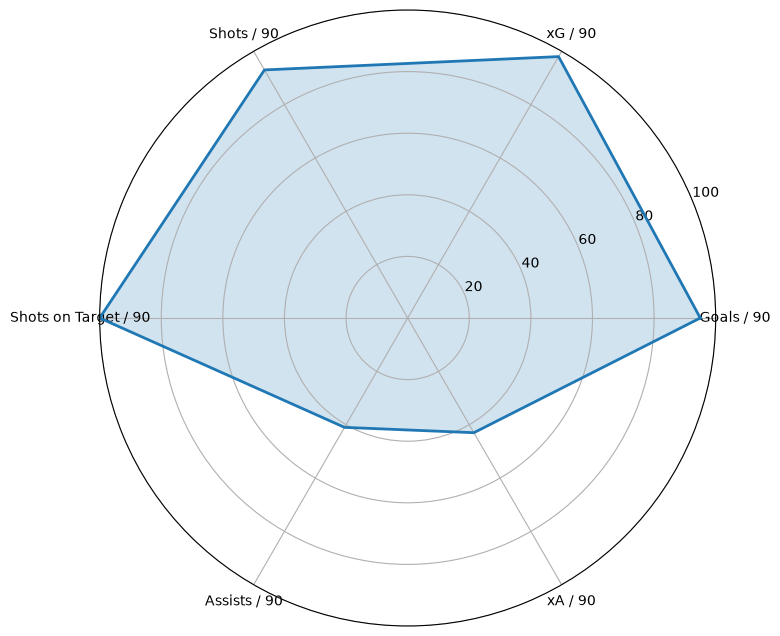

In [60]:
fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"polar": True}
)

ax.plot(
    angles_radar,
    values_radar,
    linewidth=2
)

ax.fill(
    angles_radar,
    values_radar,
    alpha=0.20
)

ax.set_xticks(angles)
ax.set_xticklabels(labels)

ax.set_ylim(0, 100)

ax.set_yticks([20, 40, 60, 80, 100])

plt.show()

In [61]:
ax.set_title(
    f"{player_name}\nPercentile profile — Striker",
    pad=25,
    fontsize=14
)

Text(0.5, 1.0, 'Samu Aghehowa\nPercentile profile — Striker')

## 9. Comparação entre jogadores

A partir dos percentis posicionais, podemos comparar jogadores que
desempenham funções semelhantes.

A comparação utiliza a mesma população de referência e as mesmas métricas
para ambos os jogadores.

In [62]:
def get_player_profile(player_name, position_group):

    metrics = metrics_by_position[position_group]

    # População de referência da posição
    reference = scouting_pool[
        scouting_pool["position_group"] == position_group
    ].copy()

    # Localiza o jogador
    player = reference[
        reference["name"] == player_name
    ]

    if player.empty:
        raise ValueError(
            f"{player_name} não encontrado em {position_group}"
        )

    player = player.iloc[0]

    profile = []

    for metric in metrics:

        percentile = (
            reference[metric]
            .rank(pct=True)
            .loc[player.name]
            * 100
        )

        profile.append({
            "metric": metric,
            "value": player[metric],
            "percentile": percentile
        })

    return pd.DataFrame(profile)

In [63]:
samu_profile = get_player_profile(
    "Samu Aghehowa",
    "Striker"
)

samu_profile

,metric,value,percentile
0,goals_per90,0.827440,92.307692
1,expectedGoals_per90,0.758839,100.000000
2,totalShots_per90,3.564356,92.307692
3,shotsOnTarget_per90,2.100424,100.000000
4,assists_per90,0.063649,46.153846
5,expectedAssists_per90,0.056994,46.153846


In [64]:
scouting_pool.loc[
    scouting_pool["position_group"] == "Striker",
    [
        "name",
        "team_name",
        "age_2025_26",
        "minutesPlayed"
    ]
].sort_values(
    "minutesPlayed",
    ascending=False
)

,name,team_name,age_2025_26,minutesPlayed
264,Marko Milovanović,FC Alverca,21.0,1535
249,Gustavo Varela,Gil Vicente,20.0,1521
125,Samu Aghehowa,FC Porto,21.0,1414
444,Deniz Gül,FC Porto,20.0,1180
367,Luís Semedo,Moreirense,21.0,989
12,Pablo Felipe,Gil Vicente,21.0,955
250,Franjo Ivanović,Benfica,21.0,885
353,Pablo Messias Cardozo,CD Nacional,22.0,866
248,Jorge Meireles,CF Estrela Amadora,21.0,758
496,Yan Maranhão,Moreirense,22.0,740


## 10. População de referência

Os jogadores candidatos ao scouting são atletas SUB-23 com pelo menos
450 minutos jogados.

Para contextualizar seu desempenho, os percentis são calculados em relação
a todos os jogadores da mesma posição com pelo menos 450 minutos,
independentemente da idade.

Dessa forma, jovens talentos são comparados ao nível geral de desempenho
da liga em sua respectiva posição.

In [65]:
benchmark_pool = analysis[
    analysis["minutesPlayed"] >= 450
].copy()

In [66]:
print("Todos os jogadores:", len(analysis))
print("Benchmark >= 450 min:", len(benchmark_pool))
print("Candidatos U23 >= 450 min:", len(scouting_pool))

Todos os jogadores: 574
Benchmark >= 450 min: 388
Candidatos U23 >= 450 min: 125


In [67]:
benchmark_pool[
    "position_group"
].value_counts(dropna=False)

position_group
Midfielder     104
Centre Back     75
Winger          71
Full Back       65
Striker         44
Goalkeeper      29
Name: count, dtype: int64

In [68]:
def get_player_profile(player_name, position_group):

    metrics = metrics_by_position[position_group]

    reference = benchmark_pool[
        benchmark_pool["position_group"] == position_group
    ].copy()

    player = scouting_pool[
        (scouting_pool["name"] == player_name) &
        (scouting_pool["position_group"] == position_group)
    ]

    if player.empty:
        raise ValueError(
            f"{player_name} não encontrado no scouting pool."
        )

    player = player.iloc[0]

    profile = []

    for metric in metrics:

        percentile_series = (
            reference[metric]
            .rank(pct=True)
            * 100
        )

        percentile = percentile_series.loc[
            reference["player_id"] == player["player_id"]
        ].iloc[0]

        profile.append({
            "metric": metric,
            "value": player[metric],
            "percentile": percentile
        })

    return pd.DataFrame(profile)

In [69]:
samu_profile = get_player_profile(
    "Samu Aghehowa",
    "Striker"
)

samu_profile.round(2)

,metric,value,percentile
0,goals_per90,0.83,95.45
1,expectedGoals_per90,0.76,97.73
2,totalShots_per90,3.56,93.18
3,shotsOnTarget_per90,2.10,100.00
4,assists_per90,0.06,40.91
5,expectedAssists_per90,0.06,43.18


In [70]:
striker_benchmark = benchmark_pool[
    benchmark_pool["position_group"] == "Striker"
].copy()

striker_benchmark[
    [
        "name",
        "age_2025_26",
        "minutesPlayed",
        "goals_per90",
        "expectedGoals_per90"
    ]
].sort_values(
    "expectedGoals_per90",
    ascending=False
).head(10)

,name,age_2025_26,minutesPlayed,goals_per90,expectedGoals_per90
4,Luis Javier Suárez,27.0,2698,0.934025,0.777346
125,Samu Aghehowa,21.0,1414,0.827440,0.758839
472,Umar Abubakar,19.0,453,0.596026,0.736649
107,Vangelis Pavlidis,26.0,2667,0.742407,0.731143
66,Guilherme Schettine,29.0,994,0.814889,0.625953
68,Jesús Ramírez,27.0,2892,0.560166,0.538130
12,Pablo Felipe,21.0,955,0.942408,0.531405
135,Yassir Zabiri,20.0,661,0.544629,0.517561
250,Franjo Ivanović,21.0,885,0.610169,0.467522
264,Marko Milovanović,21.0,1535,0.527687,0.448065


In [71]:
striker_benchmark[
    [
        "name",
        "age_2025_26",
        "shotsOnTarget_per90"
    ]
].sort_values(
    "shotsOnTarget_per90",
    ascending=False
).head(10)

,name,age_2025_26,shotsOnTarget_per90
125,Samu Aghehowa,21.0,2.100424
135,Yassir Zabiri,20.0,2.042360
4,Luis Javier Suárez,27.0,2.001483
250,Franjo Ivanović,21.0,1.830508
472,Umar Abubakar,19.0,1.788079
107,Vangelis Pavlidis,26.0,1.586052
66,Guilherme Schettine,29.0,1.539235
68,Jesús Ramírez,27.0,1.400415
249,Gustavo Varela,20.0,1.360947
31,Clayton,26.0,1.293750


In [72]:
yassir_profile = get_player_profile(
    "Yassir Zabiri",
    "Striker"
)

yassir_profile.round(2)

,metric,value,percentile
0,goals_per90,0.54,72.73
1,expectedGoals_per90,0.52,84.09
2,totalShots_per90,3.40,90.91
3,shotsOnTarget_per90,2.04,97.73
4,assists_per90,0.00,18.18
5,expectedAssists_per90,0.07,65.91


In [73]:
comparison = (
    samu_profile[
        ["metric", "percentile"]
    ]
    .rename(
        columns={"percentile": "Samu Aghehowa"}
    )
    .merge(
        yassir_profile[
            ["metric", "percentile"]
        ].rename(
            columns={"percentile": "Yassir Zabiri"}
        ),
        on="metric"
    )
)

comparison.round(0)

,metric,Samu Aghehowa,Yassir Zabiri
0,goals_per90,95.0,73.0
1,expectedGoals_per90,98.0,84.0
2,totalShots_per90,93.0,91.0
3,shotsOnTarget_per90,100.0,98.0
4,assists_per90,41.0,18.0
5,expectedAssists_per90,43.0,66.0


## 11. Comparação visual entre jogadores

O radar compara os percentis de dois jogadores da mesma posição utilizando
a mesma população de referência.

A visualização permite identificar diferenças no perfil estatístico dos
jogadores, sem combinar as métricas em um único score.

In [74]:
metric_labels = {
    "goals_per90": "Goals / 90",
    "expectedGoals_per90": "xG / 90",
    "totalShots_per90": "Shots / 90",
    "shotsOnTarget_per90": "Shots on Target / 90",
    "assists_per90": "Assists / 90",
    "expectedAssists_per90": "xA / 90"
}

comparison_plot = comparison.copy()

comparison_plot["metric"] = (
    comparison_plot["metric"]
    .map(metric_labels)
)

In [75]:
labels = comparison_plot["metric"].tolist()

samu_values = (
    comparison_plot["Samu Aghehowa"]
    .tolist()
)

yassir_values = (
    comparison_plot["Yassir Zabiri"]
    .tolist()
)

N = len(labels)

angles = np.linspace(
    0,
    2 * np.pi,
    N,
    endpoint=False
).tolist()

# Fechar o polígono
angles_radar = angles + angles[:1]

samu_radar = samu_values + samu_values[:1]
yassir_radar = yassir_values + yassir_values[:1]

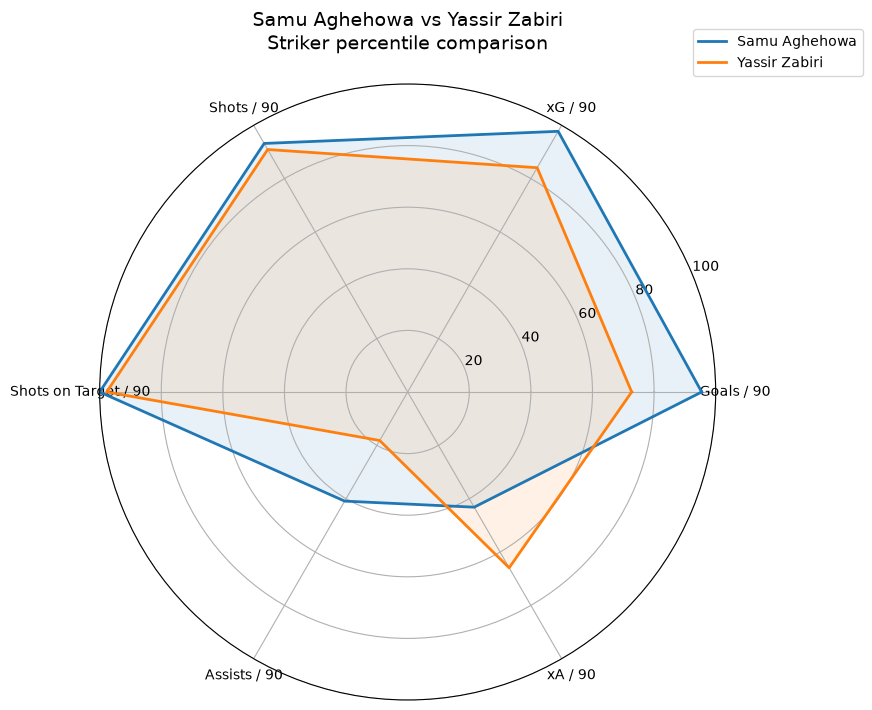

In [76]:
fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"polar": True}
)

# Samu
ax.plot(
    angles_radar,
    samu_radar,
    linewidth=2,
    label="Samu Aghehowa"
)

ax.fill(
    angles_radar,
    samu_radar,
    alpha=0.10
)

# Yassir
ax.plot(
    angles_radar,
    yassir_radar,
    linewidth=2,
    label="Yassir Zabiri"
)

ax.fill(
    angles_radar,
    yassir_radar,
    alpha=0.10
)

ax.set_xticks(angles)
ax.set_xticklabels(labels)

ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])

ax.set_title(
    "Samu Aghehowa vs Yassir Zabiri\n"
    "Striker percentile comparison",
    pad=25,
    fontsize=14
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.25, 1.10)
)

plt.show()

In [77]:
def get_player_profile(player_name):

    # Procura o jogador no scouting pool
    player = scouting_pool[
        scouting_pool["name"] == player_name
    ]

    if player.empty:
        raise ValueError(
            f"{player_name} não encontrado no scouting pool."
        )

    if len(player) > 1:
        raise ValueError(
            f"Mais de um jogador encontrado com o nome {player_name}."
        )

    player = player.iloc[0]

    position_group = player["position_group"]

    # Goleiros ainda não possuem modelo próprio
    if position_group not in metrics_by_position:
        raise ValueError(
            f"A posição {position_group} ainda não possui métricas definidas."
        )

    metrics = metrics_by_position[position_group]

    # Benchmark da mesma posição
    reference = benchmark_pool[
        benchmark_pool["position_group"] == position_group
    ].copy()

    profile = []

    for metric in metrics:

        percentile_series = (
            reference[metric]
            .rank(pct=True)
            * 100
        )

        percentile = percentile_series.loc[
            reference["player_id"] == player["player_id"]
        ].iloc[0]

        profile.append({
            "metric": metric,
            "value": player[metric],
            "percentile": percentile
        })

    return pd.DataFrame(profile)

In [78]:
samu_profile = get_player_profile(
    "Samu Aghehowa"
)

In [79]:
yassir_profile = get_player_profile(
    "Yassir Zabiri"
)

In [80]:
wingers = scouting_pool.loc[
    scouting_pool["position_group"] == "Winger",
    [
        "name",
        "team_name",
        "age_2025_26",
        "detailed_position",
        "minutesPlayed"
    ]
].sort_values(
    "minutesPlayed",
    ascending=False
)

wingers.head(10)

,name,team_name,age_2025_26,detailed_position,minutesPlayed
368,Tunde Akinsola,AVS - Futebol SAD,22.0,RW,2454
221,Noah Saviolo,Vitória SC,21.0,LW,1959
15,Andreas Schjelderup,Benfica,21.0,LW,1733
306,Ianis Stoica,CF Estrela Amadora,22.0,LW,1680
82,Gianluca Prestianni,Benfica,19.0,RW,1551
304,Oumar Camara,Vitória SC,18.0,LW,1517
427,Gabriel Martínez,Sporting Braga,22.0,ML,1327
191,Isaac James,FC Alverca,20.0,ML,1320
451,Landerson,Moreirense,18.0,ML,1290
216,Diogo Bezerra,Rio Ave,22.0,RW,1265


In [81]:
winger_name = wingers.iloc[0]["name"]

winger_profile = get_player_profile(
    winger_name
)

winger_profile.round(2)

,metric,value,percentile
0,goals_per90,0.04,22.54
1,expectedGoals_per90,0.11,29.58
2,assists_per90,0.15,57.75
3,expectedAssists_per90,0.13,52.11
4,keyPasses_per90,1.14,42.25
5,successfulDribbles_per90,1.58,67.61


## 12. Comparação genérica entre jogadores

A função abaixo permite comparar dois jogadores pertencentes ao mesmo
grupo posicional.

Os dois jogadores são avaliados utilizando as mesmas métricas e a mesma
população de referência.

In [82]:
def compare_players(player_1_name, player_2_name):

    players_selected = scouting_pool[
        scouting_pool["name"].isin(
            [player_1_name, player_2_name]
        )
    ]

    if len(players_selected) != 2:
        raise ValueError(
            "Um ou ambos os jogadores não foram encontrados."
        )

    position_1 = players_selected.loc[
        players_selected["name"] == player_1_name,
        "position_group"
    ].iloc[0]

    position_2 = players_selected.loc[
        players_selected["name"] == player_2_name,
        "position_group"
    ].iloc[0]

    if position_1 != position_2:
        raise ValueError(
            "Os jogadores devem pertencer ao mesmo grupo posicional."
        )

    profile_1 = get_player_profile(player_1_name)
    profile_2 = get_player_profile(player_2_name)

    comparison = (
        profile_1[
            ["metric", "percentile"]
        ]
        .rename(
            columns={
                "percentile": player_1_name
            }
        )
        .merge(
            profile_2[
                ["metric", "percentile"]
            ].rename(
                columns={
                    "percentile": player_2_name
                }
            ),
            on="metric"
        )
    )

    return comparison

In [83]:
comparison = compare_players(
    "Samu Aghehowa",
    "Yassir Zabiri"
)

comparison.round(0)

,metric,Samu Aghehowa,Yassir Zabiri
0,goals_per90,95.0,73.0
1,expectedGoals_per90,98.0,84.0
2,totalShots_per90,93.0,91.0
3,shotsOnTarget_per90,100.0,98.0
4,assists_per90,41.0,18.0
5,expectedAssists_per90,43.0,66.0


In [84]:
def plot_player_comparison(player_1_name, player_2_name):

    # Gera os percentis dos dois jogadores
    comparison = compare_players(
        player_1_name,
        player_2_name
    )

    # Nome amigável das métricas
    labels = [
        metric_labels.get(metric, metric)
        for metric in comparison["metric"]
    ]

    player_1_values = (
        comparison[player_1_name]
        .tolist()
    )

    player_2_values = (
        comparison[player_2_name]
        .tolist()
    )

    # Ângulos do radar
    N = len(labels)

    angles = np.linspace(
        0,
        2 * np.pi,
        N,
        endpoint=False
    ).tolist()

    # Fecha os polígonos
    angles_radar = angles + angles[:1]

    player_1_radar = (
        player_1_values + player_1_values[:1]
    )

    player_2_radar = (
        player_2_values + player_2_values[:1]
    )

    # Gráfico
    fig, ax = plt.subplots(
        figsize=(8, 8),
        subplot_kw={"polar": True}
    )

    ax.plot(
        angles_radar,
        player_1_radar,
        linewidth=2,
        label=player_1_name
    )

    ax.fill(
        angles_radar,
        player_1_radar,
        alpha=0.10
    )

    ax.plot(
        angles_radar,
        player_2_radar,
        linewidth=2,
        label=player_2_name
    )

    ax.fill(
        angles_radar,
        player_2_radar,
        alpha=0.10
    )

    ax.set_xticks(angles)
    ax.set_xticklabels(labels)

    ax.set_ylim(0, 100)
    ax.set_yticks([20, 40, 60, 80, 100])

    # Descobre a posição para o título
    position_group = scouting_pool.loc[
        scouting_pool["name"] == player_1_name,
        "position_group"
    ].iloc[0]

    ax.set_title(
        f"{player_1_name} vs {player_2_name}\n"
        f"{position_group} percentile comparison",
        pad=25,
        fontsize=14
    )

    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.25, 1.10)
    )

    plt.show()

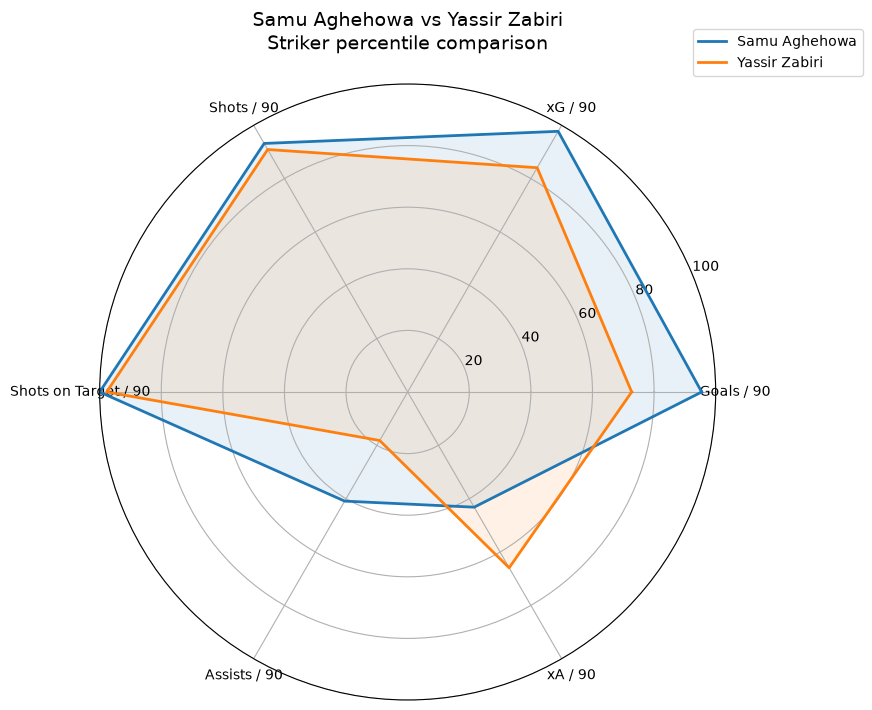

In [85]:
plot_player_comparison(
    "Samu Aghehowa",
    "Yassir Zabiri"
)

In [86]:
metric_labels = {
    "goals_per90": "Goals / 90",
    "expectedGoals_per90": "xG / 90",
    "totalShots_per90": "Shots / 90",
    "shotsOnTarget_per90": "Shots on Target / 90",
    "assists_per90": "Assists / 90",
    "expectedAssists_per90": "xA / 90",

    "keyPasses_per90": "Key Passes / 90",
    "successfulDribbles_per90": "Successful Dribbles / 90",
    "accurateFinalThirdPasses_per90": "Final Third Passes / 90",

    "ballRecovery_per90": "Ball Recoveries / 90",
    "interceptions_per90": "Interceptions / 90",
    "tackles_per90": "Tackles / 90",
    "clearances_per90": "Clearances / 90",

    "aerialDuelsWonPercentage": "Aerial Duels Won %",
    "totalDuelsWonPercentage": "Duels Won %",
    "accuratePassesPercentage": "Pass Accuracy %"
}

In [87]:
def get_player_info(player_name):

    player = scouting_pool[
        scouting_pool["name"] == player_name
    ]

    if player.empty:
        raise ValueError(
            f"{player_name} não encontrado no scouting pool."
        )

    if len(player) > 1:
        raise ValueError(
            f"Mais de um jogador encontrado com o nome {player_name}."
        )

    player = player.iloc[0]

    return {
        "player_id": player["player_id"],
        "name": player["name"],
        "team": player["team_name"],
        "age": player["age_2025_26"],
        "position": player["detailed_position"],
        "position_group": player["position_group"],
        "preferred_foot": player["preferred_foot"],
        "market_value_eur": player["market_value_eur"],
        "minutes": player["minutesPlayed"],
        "appearances": player["appearances"],
        "starts": player["matchesStarted"]
    }

In [88]:
def get_player_info(player_name):

    player = scouting_pool[
        scouting_pool["name"] == player_name
    ]

    if player.empty:
        raise ValueError(
            f"{player_name} não encontrado no scouting pool."
        )

    if len(player) > 1:
        raise ValueError(
            f"Mais de um jogador encontrado com o nome {player_name}."
        )

    player = player.iloc[0]

    return {
        "player_id": player["player_id"],
        "name": player["name"],
        "team": player["team_name"],
        "age": player["age_2025_26"],
        "position": player["detailed_position"],
        "position_group": player["position_group"],
        "height_cm": player["height_cm"],
        "preferred_foot": player["preferred_foot"],
        "country": player["country"],
        "market_value_eur": player["market_value_eur"],
        "minutes": player["minutesPlayed"],
        "appearances": player["appearances"],
        "starts": player["matchesStarted"]
    }

In [89]:
def build_player_profile(player_name):

    info = get_player_info(player_name)
    performance = get_player_profile(player_name)

    return {
        "info": info,
        "performance": performance
    }

In [90]:
samu_dashboard = build_player_profile(
    "Samu Aghehowa"
)

samu_dashboard["performance"].round(2)

,metric,value,percentile
0,goals_per90,0.83,95.45
1,expectedGoals_per90,0.76,97.73
2,totalShots_per90,3.56,93.18
3,shotsOnTarget_per90,2.10,100.00
4,assists_per90,0.06,40.91
5,expectedAssists_per90,0.06,43.18


In [91]:
def get_player_kpis(player_name):

    profile = get_player_profile(player_name)

    kpis = {}

    for _, row in profile.iterrows():

        kpis[row["metric"]] = {
            "value": row["value"],
            "percentile": row["percentile"]
        }

    return kpis

In [92]:
samu_info

NameError: name 'samu_info' is not defined

In [ ]:
samu_dashboard = build_player_profile(
    "Samu Aghehowa"
)

samu_kpis = get_player_kpis(
    "Samu Aghehowa"
)

samu_kpis

{'goals_per90': {'value': 0.8274398868458275, 'percentile': 95.45454545454545},
 'expectedGoals_per90': {'value': 0.7588387553041018,
  'percentile': 97.72727272727273},
 'totalShots_per90': {'value': 3.5643564356435644,
  'percentile': 93.18181818181817},
 'shotsOnTarget_per90': {'value': 2.1004243281471005, 'percentile': 100.0},
 'assists_per90': {'value': 0.06364922206506365,
  'percentile': 40.909090909090914},
 'expectedAssists_per90': {'value': 0.05699449603960396,
  'percentile': 43.18181818181818}}

In [93]:
import sys
from pathlib import Path

# Localiza a raiz do projeto
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.scouting import load_data, prepare_analysis

# Carrega os dados do projeto
df = load_data()

# Cria a tabela de análise
analysis = prepare_analysis(df)

print("df:", df.shape)
print("analysis:", analysis.shape)

analysis[
    ["player_id", "name", "team_name", "position_group"]
].head()

df: (574, 129)
analysis: (574, 159)


,player_id,name,team_name,position_group
0,1961855,João Afonso,Santa Clara,Goalkeeper
1,1001196,Gonçalo Inácio,Sporting CP,Centre Back
2,983550,Samuel Soares,Benfica,Goalkeeper
3,1961117,José Neto,Benfica,Full Back
4,914213,Luis Javier Suárez,Sporting CP,Striker
